## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


**Answer**

The estimate of the ATE is -0.01, meaning patients in Group A (invasive strategy) had about a 1 percentage-point lower survival rate than those in Group B (conservative strategy). Based on this result, I would rather not get the intra-aortic balloon pump. However, the difference is very small, so we cannot be sure whether it reflects a real treatment effect or random chance.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

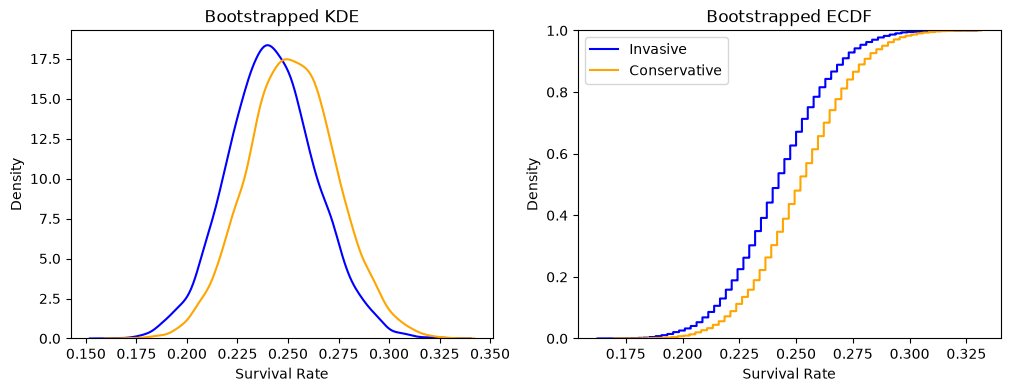

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**Answer**

The KDE plots show that both groups have roughly bell-shaped curves that overlap a lot, with most values near the center. The invasive group is centered around 24.5%, while the conservative group is centered around 25.5%. The conservative group's curve is slightly shifted to the right, showing a slightly higher survival rate.

The ECDF plots have a staircase shape but kinda smooth because they show the percentage of estimates below each survival rate.The invasive group's curve rises earlier and stays higher than the conservative group's curve. A higher ECDF curve means that more estimates are at or below the same survival rate, so the invasive group tends to have lower survival rates. The conservative group's curve stays slightly lower and to the right, meaning its estimates tend to have higher survival rates.

Overall, both plots show that the two groups are very similar, and the difference between them is small compared to the variation in the bootstrap estimates.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

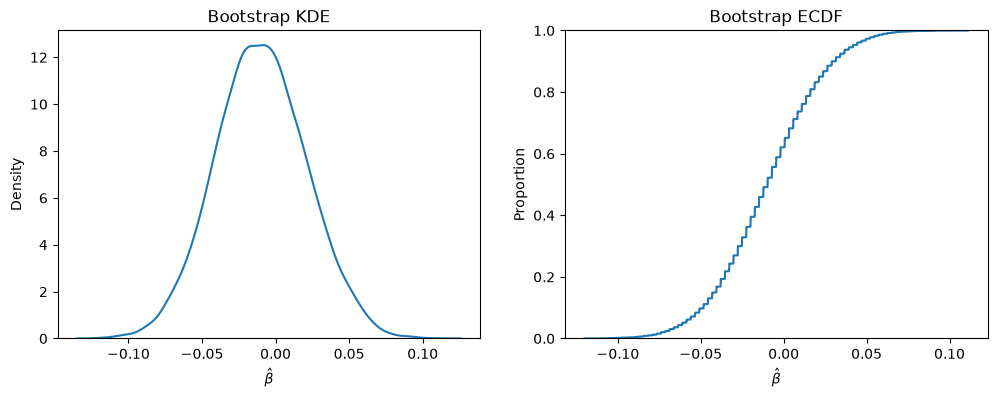

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**Answer**
The KDE plot shows that the bootstrap sampling distribution of the ATE is roughly bell-shaped and centered around -0.01, with most estimates between approximately -0.07 and 0.04 and fewer values near the ends of -0.10 and 0.10. The ECDF increases slowly at first, rises faster near the center where most estimates are concentrated, and then levels off close to 1. Based on the plots, the ATE estimates range approximately from -0.10 to 0.10, showing that the bootstrap estimates include both negative and positive values. This shows that there is some uncertainty in the estimated treatment effect.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [7]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06110036  0.04182016]
95% CI: [-0.06889858  0.05210293]
99% CI: [-0.08942438  0.06768488]


**Answer**
The 90% confidence interval is [-0.0611, 0.0418], the 95% confidence interval is [-0.0689, 0.0521], and the 99% confidence interval is [-0.0894, 0.0677]. All three confidence intervals contain zero. Therefore, we fail to reject the null hypothesis that the true ATE is zero at all three confidence levels, and we do not reject it at any level. There is insufficient evidence to conclude that the intra-aortic balloon pump has an effect on survival compared to conservative treatment.

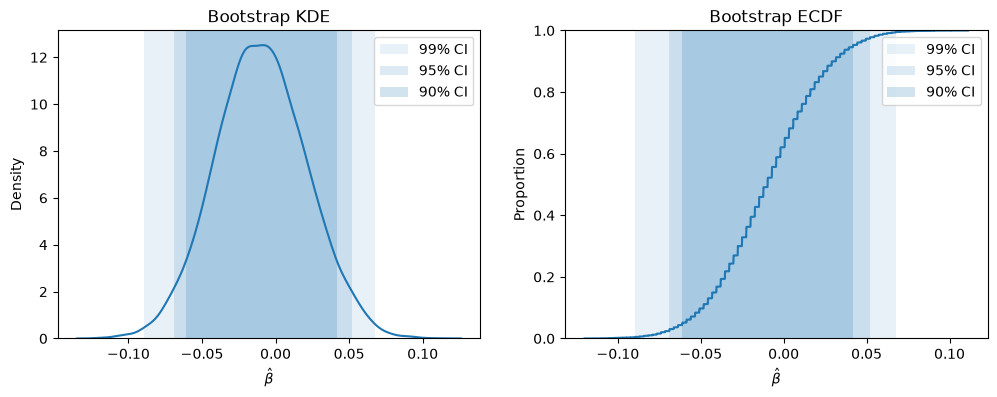

In [8]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

**Answer**
The estimated ATE is approximately -0.01, meaning that the Invasive group had a survival rate about 1 percentage point lower than the Conservative group in this sample. However, all three bootstrap confidence intervals (90%, 95%, and 99%) include zero, so we fail to reject the null hypothesis that the true ATE is zero. This means there is not enough evidence to conclude that one treatment is more effective than the other in improving survival. However, this does not necessarily mean that both treatments are equally effective.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

part 2:

1.

In [10]:

##Load data
df = pd.read_csv('./data/diabetes.csv')

## Crosstabs
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

# Average outcomes (success = 1, failure = 0)
df['success'] = (df['outcome'] == 'success').astype(int)

print(df.groupby('treatment')['success'].mean().round(3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: success, dtype: float64


The average outcomes are 0.534 (53.4%) for lifestyle, 0.483 (48.3%) for met, and 0.614 (61.4%) for rosi. The rosi group has the highest success rate, followed by lifestyle and met has the lowest success rate. Based on these results, rosi appears to have the best outcome among the three treatment groups in this sample.

2.

In [11]:
# Bootstrapping:
R = 10_000

df_a = df.loc[df['treatment'] == 'lifestyle', :]
df_b = df.loc[df['treatment'] == 'met', :]
df_c = df.loc[df['treatment'] == 'rosi', :]

outcome_a = []
outcome_b = []
outcome_c = []

for t in range(R):
    ## Resample within each group:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['success'].mean()
    obt = df_bt['success'].mean()
    oct = df_ct['success'].mean()

    ## Store results:
    outcome_a.append(oat)
    outcome_b.append(obt)
    outcome_c.append(oct)

3.

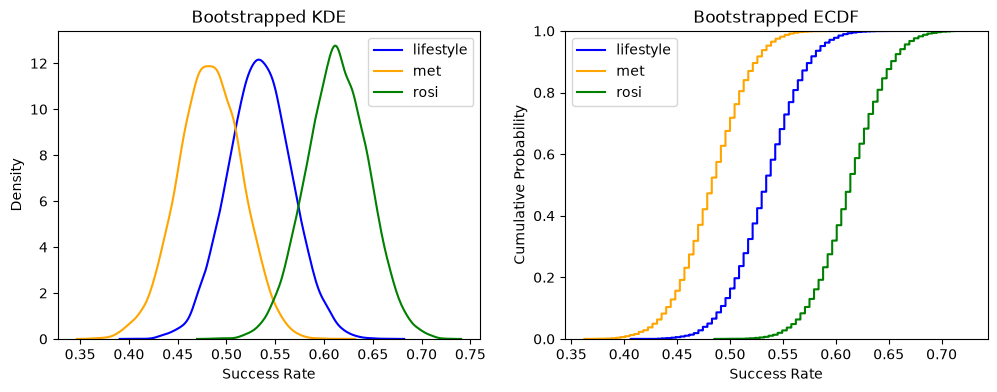

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='met', color='orange', ax=ax[0])
sns.kdeplot(outcome_c, label='rosi', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='met', color='orange', ax=ax[1])
sns.ecdfplot(outcome_c, label='rosi', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Cumulative Probability')

ax[0].legend()
ax[1].legend()

plt.show()

**Answer**

The KDE plots show that all three groups have roughly bell-shaped distributions. The Rosi group is centered around 61.4%, showing the highest success rate, followed by Lifestyle at 53.4%, while Met is centered around 48.3%, showing the lowest success rate. The distributions overlap, especially between Met and Lifestyle, indicating uncertainty about the differences in their success rates. However, Rosi is more clearly separated from the other two groups to the right. The ECDF plots show a similar pattern, with Met rising first on the left, followed by Lifestyle, and Rosi rising last on the right. This means that Rosi generally has higher estimated success rates, while Met has lower estimated success rates. The plots show that Rosi performs best in this sample, followed by Lifestyle and then Met.

4. 

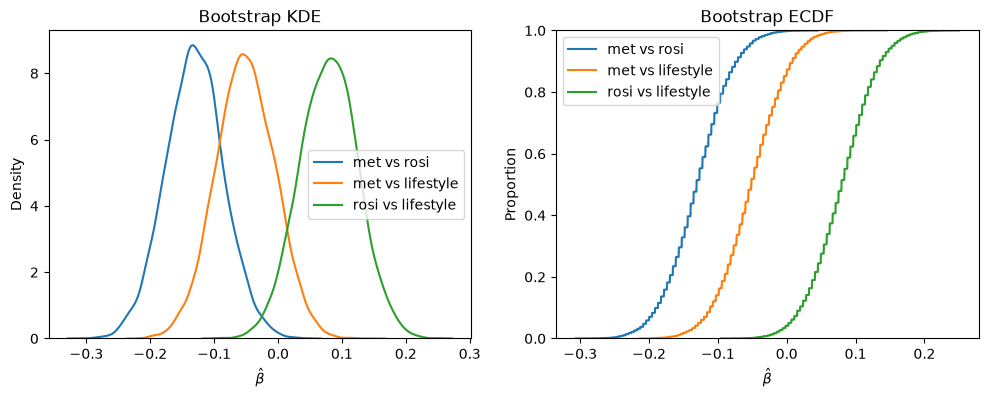

In [16]:
## Calculate the three treatment effects
ate_met_rosi = np.array(outcome_b) - np.array(outcome_c)
ate_met_lifestyle = np.array(outcome_b) - np.array(outcome_a)
ate_rosi_lifestyle = np.array(outcome_c) - np.array(outcome_a)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_met_rosi, label='met vs rosi', ax=ax[0])
sns.kdeplot(ate_met_lifestyle, label='met vs lifestyle', ax=ax[0])
sns.kdeplot(ate_rosi_lifestyle, label='rosi vs lifestyle', ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate_met_rosi, label='met vs rosi', ax=ax[1])
sns.ecdfplot(ate_met_lifestyle, label='met vs lifestyle', ax=ax[1])
sns.ecdfplot(ate_rosi_lifestyle, label='rosi vs lifestyle', ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

plt.show()

In [17]:
print("met vs rosi:", np.mean(ate_met_rosi))
print("met vs lifestyle:", np.mean(ate_met_lifestyle))
print("rosi vs lifestyle:", np.mean(ate_rosi_lifestyle))

met vs rosi: -0.13053517833357997
met vs lifestyle: -0.051124329501915707
rosi vs lifestyle: 0.07941084883166429


**Answer**
The bootstrap KDE and ECDF plots show the estimated differences in success rates between the three treatments. Met has a lower estimated success rate than Rosi by about 13.1 percentage points and a lower rate than Lifestyle by about 5.1 percentage points. Rosi has a higher estimated success rate than Lifestyle by about 7.9 percentage points. The Met vs Rosi distribution is mostly below zero, suggesting that Rosi performs better than Met. However, the Met vs Lifestyle and Rosi vs Lifestyle distributions include both positive and negative values, showing more uncertainty about which treatment performs better. We need Confidence intervals to determine whether these differences are statistically significant. Statistical significance helps us determine whether the differences in success rates between Met, Rosi, and Lifestyle provide convincing evidence that one treatment is more effective than another.

5.

In [18]:
## met vs rosi
ci90_met_rosi = np.quantile(ate_met_rosi, [.05, .95])
ci95_met_rosi = np.quantile(ate_met_rosi, [.025, .975])
ci99_met_rosi = np.quantile(ate_met_rosi, [.005, .995])

print("met vs rosi")
print(f"90% CI: {ci90_met_rosi}")
print(f"95% CI: {ci95_met_rosi}")
print(f"99% CI: {ci99_met_rosi}\n")

## met vs lifestyle
ci90_met_lifestyle = np.quantile(ate_met_lifestyle, [.05, .95])
ci95_met_lifestyle = np.quantile(ate_met_lifestyle, [.025, .975])
ci99_met_lifestyle = np.quantile(ate_met_lifestyle, [.005, .995])

print("met vs lifestyle")
print(f"90% CI: {ci90_met_lifestyle}")
print(f"95% CI: {ci95_met_lifestyle}")
print(f"99% CI: {ci99_met_lifestyle}\n")

## rosi vs lifestyle
ci90_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.05, .95])
ci95_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.025, .975])
ci99_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.005, .995])

print("rosi vs lifestyle")
print(f"90% CI: {ci90_rosi_lifestyle}")
print(f"95% CI: {ci95_rosi_lifestyle}")
print(f"99% CI: {ci99_rosi_lifestyle}\n")

met vs rosi
90% CI: [-0.20417715 -0.05364807]
95% CI: [-0.22125203 -0.04066154]
99% CI: [-0.24705861 -0.01054462]

met vs lifestyle
90% CI: [-0.12835433  0.02567971]
95% CI: [-0.14157825  0.03861074]
99% CI: [-0.17141928  0.06447115]

rosi vs lifestyle
90% CI: [0.00260445 0.15254576]
95% CI: [-0.01032657  0.16939997]
99% CI: [-0.03616889  0.19507731]



**Answer**

The bootstrap confidence intervals show a statistically significant difference between Met and Rosi at the 90%, 95%, and 99% confidence levels because all three intervals are negative and exclude zero. This provides strong evidence that Rosi has a higher success rate than Met. For Met vs Lifestyle, all three intervals include zero, meaning there is not enough evidence to conclude that one treatment is more effective than the other. For Rosi vs Lifestyle, the 90% confidence interval is positive and excludes zero, indicating a statistically significant difference at the 10% significance level. However, the 95% and 99% intervals include zero, so the evidence is not strong enough to establish a significant difference at those levels. Overall, Rosi appears to be the most effective treatment, with the highest observed success rate of 61.4%, followed by Lifestyle at 53.4% and Met at 48.3%. However, Rosi's advantage over Lifestyle is less statistically certain than its advantage over Met.